In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import xarray as xr
import numpy as np
import geopandas as gpd

# 1. NDVI

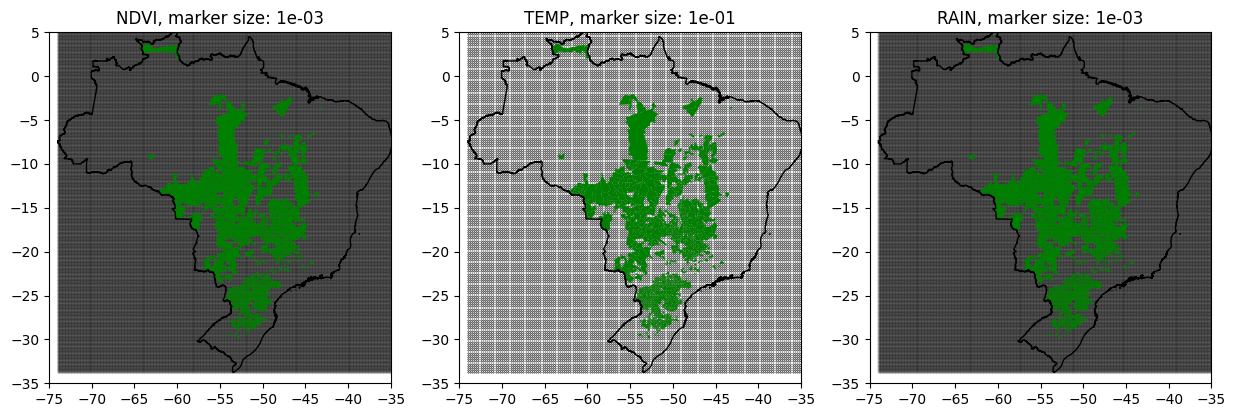

In [2]:
fig, ax = plt.subplots(figsize=(15, 10), ncols=3, nrows=1)
gdf_br = gpd.read_file(r"Bases/BR_Pais_2024/BR_Pais_2024.shp").to_crs("EPSG:4326").boundary
muns = gpd.read_file(r"Bases/municipios_em_uso.shp").to_crs("EPSG:4326")

def gera_gdf(var):
    if var == 'ndvi':
        var_file = r"Z:\Analytics & BI\Bases de dados\NDVI\ndvi_soja_mensal.nc"
        crs_to_use = "EPSG:4326"
    elif var == 'temp':
        var_file = r"Z:\Analytics & BI\Bases de dados\ERA5 - Temperature monthly\temperature_soja_mensal.nc"
        crs_to_use = "EPSG:4326"
    elif var == 'rain':
        var_file = r"Z:\Analytics & BI\Bases de dados\CHIRPS - Monthly\full_rain_soja_mensal.nc"
        crs_to_use = "EPSG:4326"
    else:
        raise(ValueError, "Should be ndvi, temp or rain")

    test_ds = xr.open_dataset(var_file)

    lats, lons = test_ds['latitude'].values, test_ds['longitude'].values

    if lats[0] < lats[-1]:
        lats = lats[::-1] 

    if lons[0] > lons[-1]:
        lons = lons[::-1]  # inverte longitudes

    lon_grid, lat_grid = np.meshgrid(lons, lats)
    lon_flat, lat_flat = lon_grid.ravel(), lat_grid.ravel()

    gdf = gpd.GeoDataFrame(
        {'lon': lon_flat, 'lat': lat_flat},
        geometry=gpd.points_from_xy(lon_flat, lat_flat),
        crs=crs_to_use
        )

    gdf = gdf.to_crs("EPSG:4326")
    return gdf

sizes = [0.001, 0.1, 0.001]

for i, v in enumerate(['ndvi', 'temp', 'rain']):
    gdf = gera_gdf(v)
    gdf.plot(ax=ax[i], color='black', markersize=sizes[i])
    gdf_br.plot(ax=ax[i], color='black', linewidth=1)
    muns.plot(ax=ax[i], color='g', markersize=1)
    ax[i].set_xlim(-75, -35)
    ax[i].set_ylim(-35, 5)
    ax[i].set_title(f"{v.upper()}, marker size: {sizes[i]:.0e}")

plt.show()

3. Precipitacao

In [2]:
df = pd.concat(
    [pd.read_csv(r"Bases\range(2005, 2011)_final_data.csv"),
    pd.read_csv(r"Bases\range(2010, 2016)_final_data.csv"),
    pd.read_csv(r"Bases\range(2015, 2021)_final_data.csv"),
    pd.read_csv(r"Bases\range(2020, 2025)_final_data.csv"),
    pd.read_csv(r"Bases\range(2024, 2026)_final_data.csv")
    ]
    ).reset_index(drop=True)

df.sample(5, random_state=42)

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,precip_12_ly,precip_01,precip_02,ndvi_10_ly,ndvi_11_ly,ndvi_12_ly,ndvi_01,ndvi_02,ndvi_03,PROD_SOJA
10650,Cabeceiras,GO,2016,37.538240,35.845610,34.080963,32.089996,33.382477,31.700533,149.86075,120.00781,323.60596,58.334606,0.327105,0.435255,0.500005,0.701300,0.726174,0.600274,2900.0
2041,Ipuaçu,SC,2007,32.698395,32.074370,33.544098,30.812408,30.685944,144.675230,174.53810,210.34612,180.87419,166.961780,0.633320,0.638960,0.729940,0.820250,0.835080,0.754980,2500.0
8668,Reserva do Iguaçu,PR,2014,28.527008,30.050201,29.452790,30.604645,31.803620,135.243450,108.04855,188.46315,203.37184,120.803270,0.715817,0.721980,0.761687,0.820937,0.828090,0.777027,3380.0
1114,Colorado,RS,2010,33.974030,35.486970,32.670074,32.546783,35.292145,134.427690,369.50186,169.60869,215.09729,176.798510,0.587950,0.427270,0.458850,0.823040,0.845480,0.738500,3300.0
13902,Santa Cruz do Rio Pardo,SP,2018,36.388092,33.132477,34.430573,33.635162,34.088776,220.162310,125.28750,193.55215,261.44702,156.910480,0.481145,0.574143,0.685530,0.786375,0.698050,0.649730,3600.0


Text(0, 0.5, 'Produtividade média')

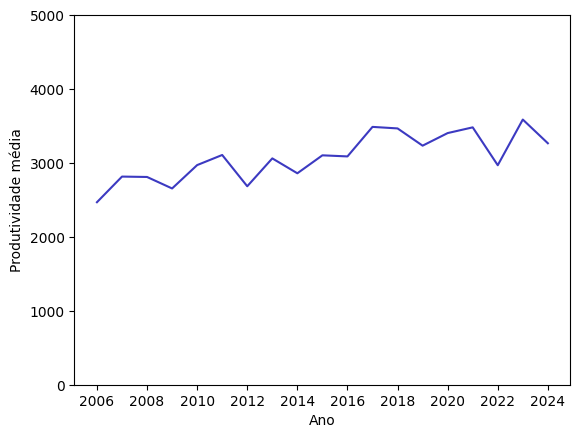

In [3]:
prod = df.groupby(['NM_MUN', 'SIGLA_UF', 'YEAR'])['PROD_SOJA'].first().reset_index()
prod = prod.groupby('YEAR')['PROD_SOJA'].mean().reset_index()

plt.plot(prod['YEAR'], prod['PROD_SOJA'], color="#0E0BB3CE")
plt.xlabel("Ano")
plt.xticks(prod['YEAR'][::2])
plt.ylim(0, 5000)
plt.ylabel('Produtividade média')

In [111]:
1 - prod[prod['YEAR'] == 2022]['PROD_SOJA'].values[0]/prod[prod['YEAR'] == 2021]['PROD_SOJA'].values[0]

np.float64(0.14715504760088494)

In [113]:
df[df['YEAR'] < 2025].groupby(['SIGLA_UF'])['PROD_SOJA'].mean()

SIGLA_UF
BA    3164.298246
DF    3274.052632
GO    3084.828255
MA    2874.005263
MG    3112.309058
MS    3007.778677
MT    3178.776157
PA    2985.173684
PI    2976.986842
PR    3124.154003
RO    3238.427632
RR    2848.473684
RS    2983.062500
SC    3050.810150
SP    3069.256073
TO    2924.182456
Name: PROD_SOJA, dtype: float64

In [3]:
df2 = df.copy()

# Separe colunas fixas de colunas de clima
id_vars = ['NM_MUN', 'SIGLA_UF', 'YEAR']
value_vars = [c for c in df.columns if c not in id_vars]

# Transformar em longo
tmp = df2.melt(id_vars=id_vars, value_vars=value_vars,
               var_name='var_mes', value_name='valor')

tmp['ly'] = tmp['var_mes'].str.endswith('_ly')
tmp['var'] = tmp['var_mes'].str.extract(r'^(.*?)_')
tmp['mes'] = tmp['var_mes'].str.extract(r'_(\d{2})')

tmp['ANO'] = tmp['YEAR'] - tmp['ly'].astype(int)

tmp['DATA'] = pd.to_datetime(tmp['ANO'].astype(str) + "-" + tmp['mes'] + "-01")

satelite = tmp.pivot_table(
    index=['NM_MUN', 'SIGLA_UF', 'DATA'],
    columns='var',
    values='valor'
).reset_index()

# Ordenar colunas
satelite = satelite[['NM_MUN', 'SIGLA_UF', 'DATA', 't2m', 'precip', 'ndvi']]
satelite['NM_MUN'] = satelite['NM_MUN'].str.title().str.replace("â", "a").str.replace("ê", "e").str.replace("ó", "o")
satelite


var,NM_MUN,SIGLA_UF,DATA,t2m,precip,ndvi
0,Abadia Dos Dourados,MG,2005-10-01,36.325348,46.527298,0.426203
1,Abadia Dos Dourados,MG,2005-11-01,32.268220,343.472930,0.482027
2,Abadia Dos Dourados,MG,2005-12-01,31.128326,322.734130,0.618993
3,Abadia Dos Dourados,MG,2006-01-01,33.847810,201.279720,0.634220
4,Abadia Dos Dourados,MG,2006-02-01,31.330475,154.099430,0.653433
...,...,...,...,...,...,...
119995,Óleo,SP,2024-11-01,35.458405,121.424140,0.522600
119996,Óleo,SP,2024-12-01,32.603424,236.099500,0.691450
119997,Óleo,SP,2025-01-01,32.298004,137.532750,0.754650
119998,Óleo,SP,2025-02-01,33.975250,117.279106,0.776700


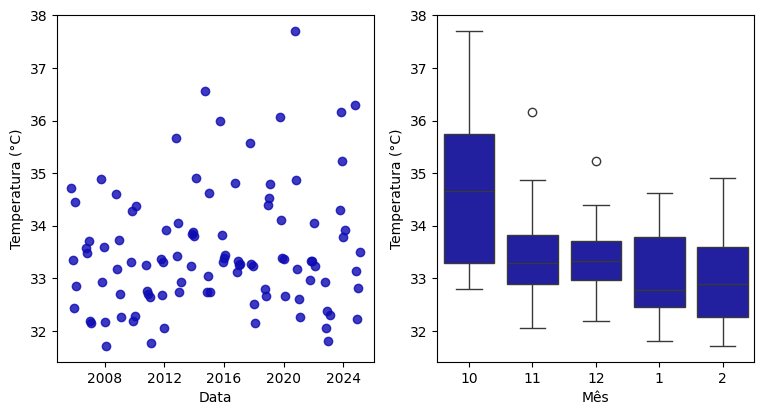

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax = ax.flatten()

ndvi_med = satelite.groupby('DATA')['t2m'].mean().dropna().reset_index()
ax[0].scatter(ndvi_med['DATA'], ndvi_med['t2m'], color="#0E0BB3CE")
ax[0].set_xlabel("Data")
ax[0].set_ylabel('Temperatura (°C)')

ndvi_med['Mes'] = ndvi_med['DATA'].dt.month
meses_ordem = ['10', '11', '12', '1', '2']

ax[1].set_xlabel("Mês")
ax[1].set_ylabel('Temperatura (°C)')

sns.boxplot(x='Mes', y='t2m', data=ndvi_med, color="#0E0BB3CE", ax=ax[1], order=[10, 11, 12, 1, 2])
plt.show()

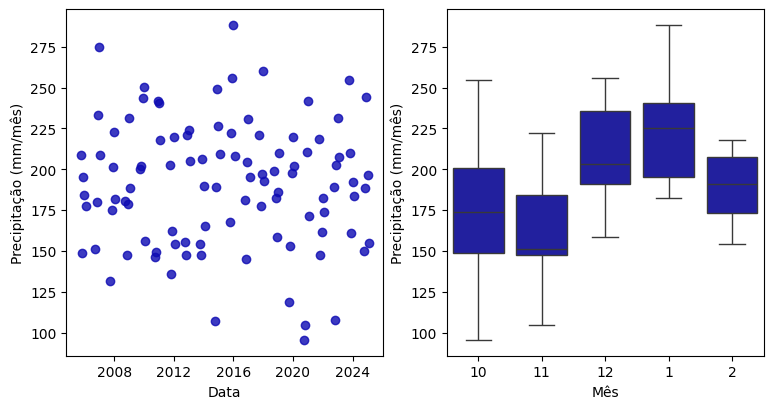

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax = ax.flatten()

ndvi_med = satelite.groupby('DATA')['precip'].mean().dropna().reset_index()
ax[0].scatter(ndvi_med['DATA'], ndvi_med['precip'], color="#0E0BB3CE")
ax[0].set_xlabel("Data")
ax[0].set_ylabel('Precipitação (mm/mês)')

ndvi_med['Mes'] = ndvi_med['DATA'].dt.month
meses_ordem = ['10', '11', '12', '1', '2']

ax[1].set_xlabel("Mês")
ax[1].set_ylabel('Precipitação (mm/mês)')

sns.boxplot(x='Mes', y='precip', data=ndvi_med, color="#0E0BB3CE", ax=ax[1], order=[10, 11, 12, 1, 2])
plt.show()

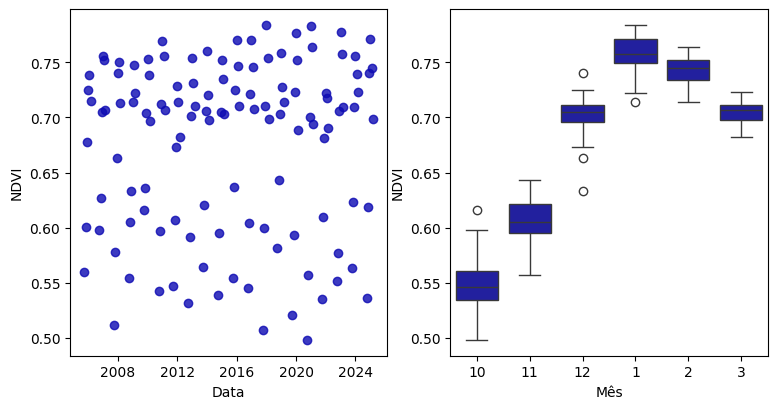

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax = ax.flatten()

ndvi_med = satelite.groupby('DATA')['ndvi'].mean().dropna().reset_index()
ax[0].scatter(ndvi_med['DATA'], ndvi_med['ndvi'], color="#0E0BB3CE")
ax[0].set_xlabel("Data")
ax[0].set_ylabel('NDVI')

ndvi_med['Mes'] = ndvi_med['DATA'].dt.month
meses_ordem = ['10', '11', '12', '1', '2']

ax[1].set_xlabel("Mês")
ax[1].set_ylabel('NDVI')

sns.boxplot(x='Mes', y='ndvi', data=ndvi_med, color="#0E0BB3CE", ax=ax[1], order=[10, 11, 12, 1, 2, 3])
plt.show()

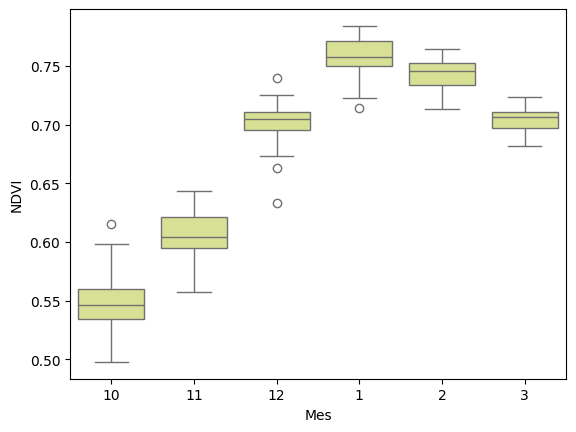

In [9]:
sns.boxplot(x='Mes', y='ndvi', data=ndvi_med, color="#E0EC89", order=[10, 11, 12, 1, 2, 3])
plt.ylabel('NDVI')
plt.show()

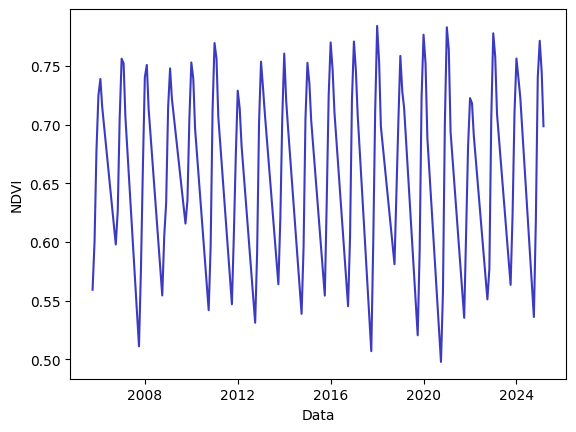

In [59]:
plt.plot(ndvi_med['DATA'], ndvi_med['ndvi'], color="#0E0BB3CE")
plt.xlabel("Data")
plt.ylabel('NDVI')
plt.show()

In [6]:
satelite2 = satelite[satelite['DATA'].dt.year < 2025]
print(satelite2['precip'].mean(), satelite2['t2m'].mean())

191.11908414714594 33.523032424367344


In [65]:
print(100*0.63/33.52, 100*1.69/33.52, 100*38.82/191.12, 100*138.37/191.12)

1.8794749403341287 5.041766109785202 20.31184596065299 72.3995395562997


In [8]:
cidades_com_estacao = [
    "Alta Floresta",
    "Alto Taquari",
    "Castro",
    "Xinguara",
    "Chapeco",
    "Barra",  # BA
    "Uberlandia",
    "Xanxere",
    "Uberaba",
    "Pires Do Rio",
]

In [9]:
satelite = satelite[satelite['NM_MUN'].isin(cidades_com_estacao)]
satelite

var,NM_MUN,SIGLA_UF,DATA,t2m,precip,ndvi
2880,Alto Taquari,MT,2005-10-01,35.987457,121.48001,0.500055
2881,Alto Taquari,MT,2005-11-01,32.734528,191.35905,0.546992
2882,Alto Taquari,MT,2005-12-01,31.763336,229.30177,0.623594
2883,Alto Taquari,MT,2006-01-01,33.728912,227.27072,0.710362
2884,Alto Taquari,MT,2006-02-01,31.449860,268.78455,0.736391
...,...,...,...,...,...,...
118435,Xanxere,SC,2024-11-01,31.055328,145.17273,0.631462
118436,Xanxere,SC,2024-12-01,29.362946,148.08011,0.756046
118437,Xanxere,SC,2025-01-01,32.465730,135.67342,0.804854
118438,Xanxere,SC,2025-02-01,31.760406,165.12315,0.776892


In [37]:
print(satelite[['NM_MUN', 'SIGLA_UF']].drop_duplicates()[['NM_MUN', 'SIGLA_UF']].to_latex(index=False))

\begin{tabular}{ll}
\toprule
NM_MUN & SIGLA_UF \\
\midrule
Alto Taquari & MT \\
Castro & PR \\
Chapeco & SC \\
Pires Do Rio & GO \\
Uberaba & MG \\
Uberlandia & MG \\
Xanxere & SC \\
\bottomrule
\end{tabular}



# gerar dados de prec e temp dnv 

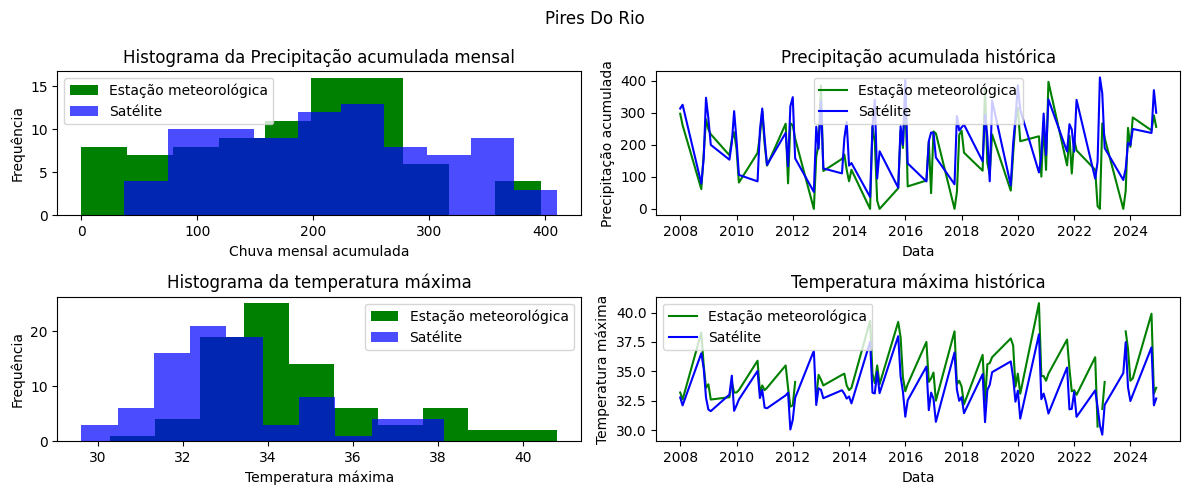

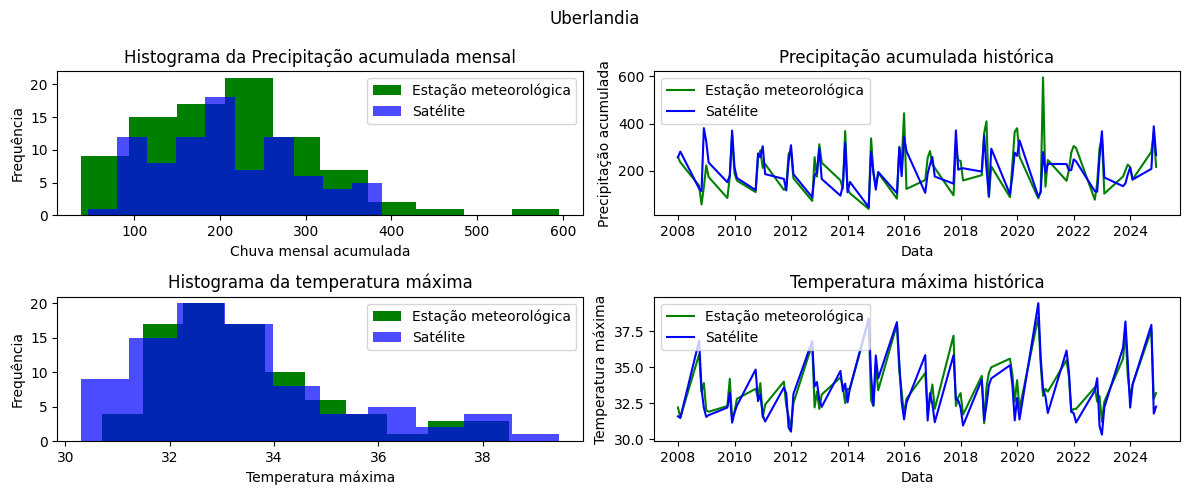

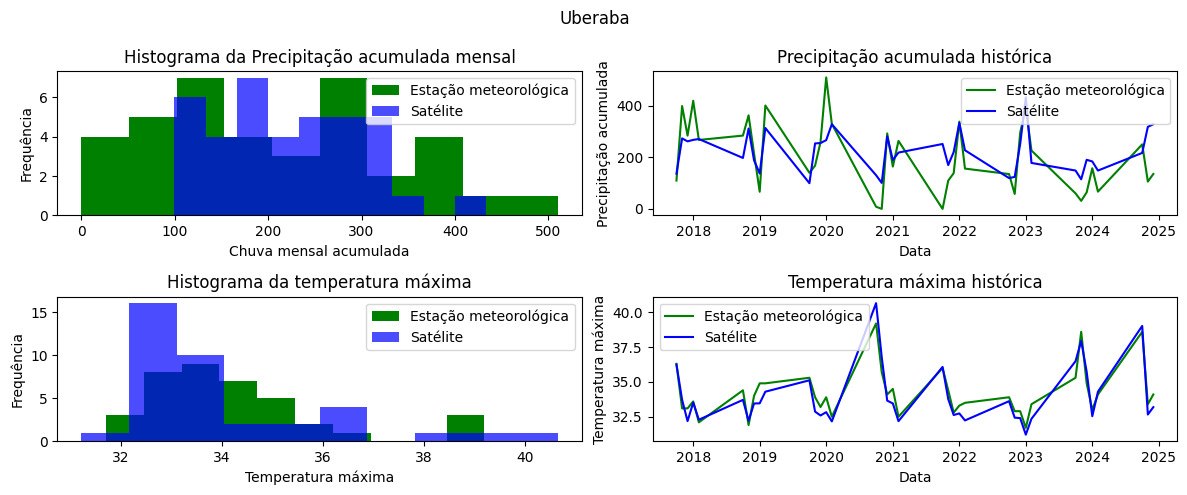

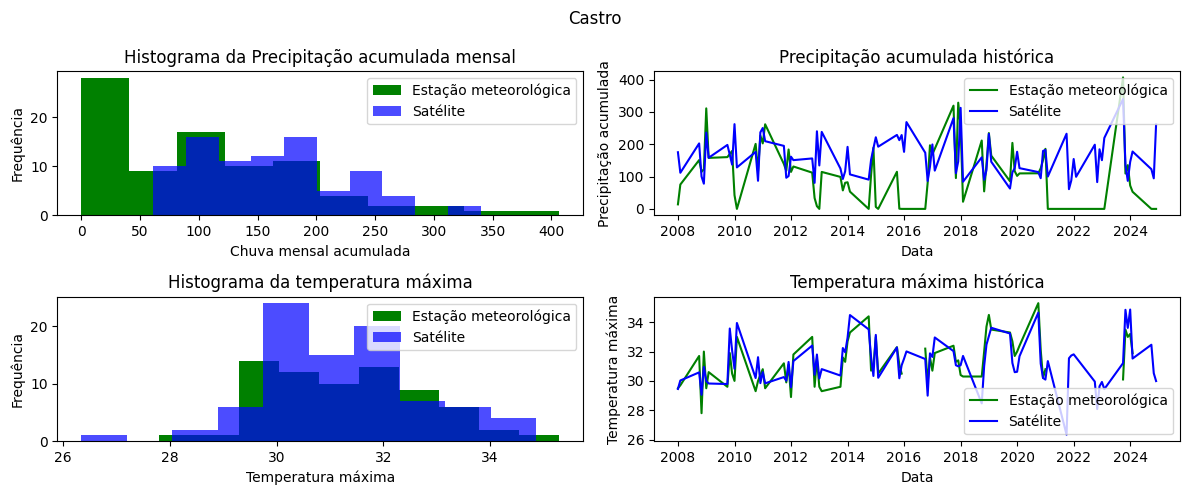

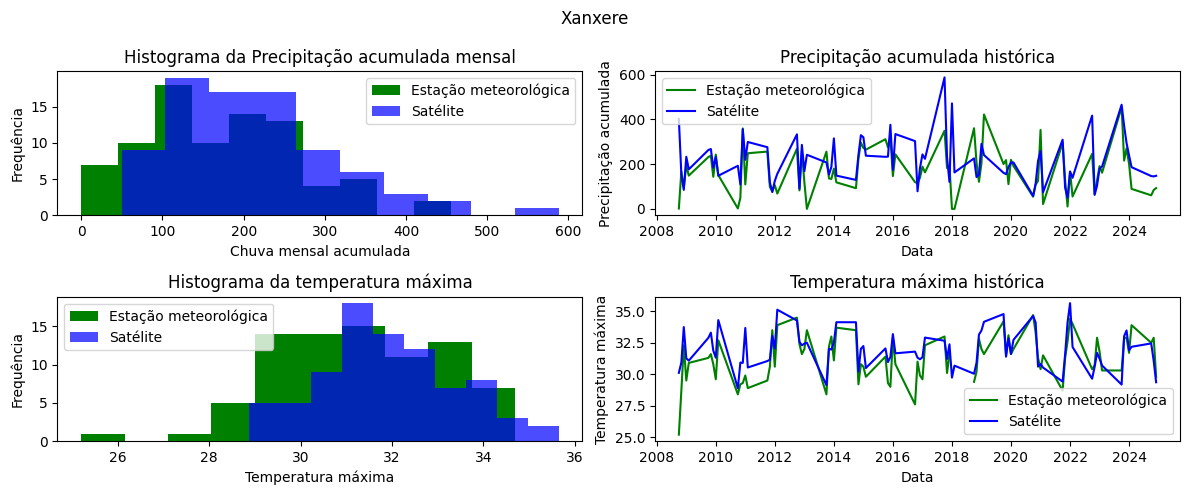

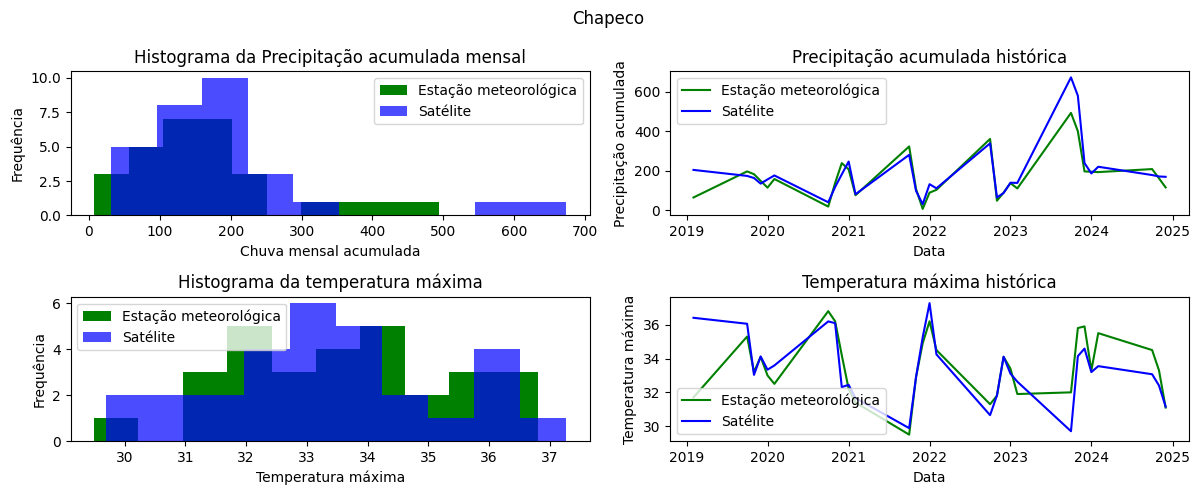

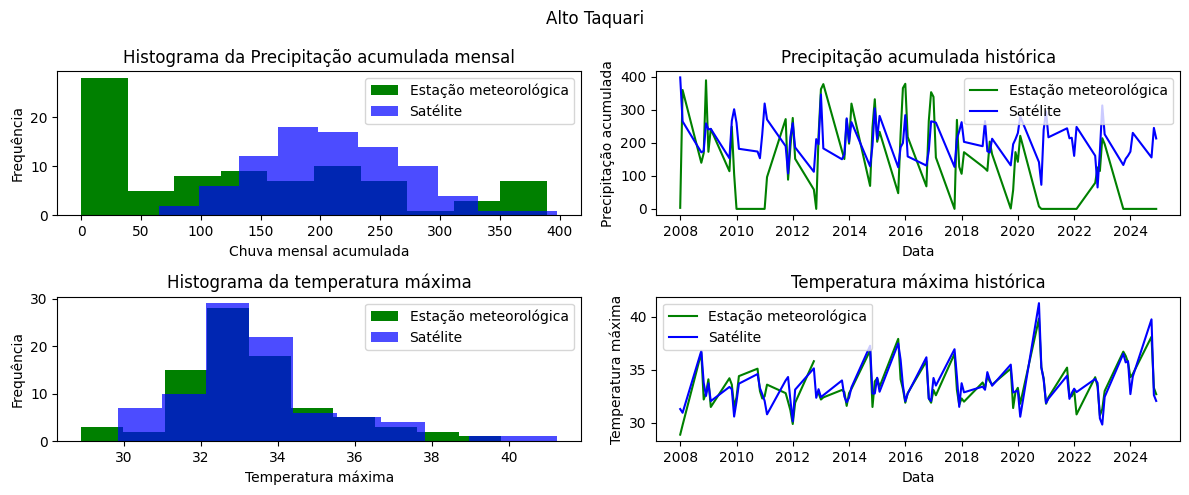

In [12]:
for file in os.listdir(r"Bases\Dados INMET - validacao"):
    aux_name = pd.read_csv("Bases/Dados INMET - validacao/" + file, nrows=0).columns[0].split(':')[1].strip().title()
    if aux_name not in satelite['NM_MUN'].unique():
        continue

    aux = pd.read_csv("Bases/Dados INMET - validacao/" + file, skiprows=10, sep=';')
    aux.columns = ['Data', 'precip_inmet', 'temp_inmet', 'fodase']
    aux = aux[['Data', 'precip_inmet', 'temp_inmet']]
    aux['Data'] = pd.to_datetime(aux['Data'], format='%Y-%m-%d').dt.to_period('M').dt.to_timestamp()
    aux = aux[aux['Data'].dt.month.isin([1, 2, 10, 11, 12])]
    
    aux = aux.groupby('Data').agg({
        'precip_inmet': 'sum',
        'temp_inmet': 'max'
        }).reset_index()
    
    fig, ax = plt.subplots(2, 2, figsize=(12,5))
    axes = ax.flatten()

    satelite_aux = satelite[satelite['NM_MUN'] == aux_name]
    satelite_aux = satelite_aux[satelite_aux['DATA'].dt.month.isin([1, 2, 10, 11, 12])]
    start = max(aux['Data'].min(), satelite_aux['DATA'].min())
    end   = min(aux['Data'].max(), satelite_aux['DATA'].max())
    aux = aux[(aux['Data'] >= start) & (aux['Data'] <= end)]
    satelite_aux = satelite_aux[(satelite_aux['DATA'] >= start) & (satelite_aux['DATA'] <= end)]

    ### Histograma precipitacao
    axes[0].set_title("Histograma da Precipitação acumulada mensal")
    
    axes[0].hist(aux['precip_inmet'], color='g', label='Estação meteorológica')
    axes[0].hist(satelite_aux['precip'], color='b', label='Satélite', alpha=0.7)

    axes[0].set_xlabel('Chuva mensal acumulada')
    axes[0].legend()

    ### Plot de precipitacao
    axes[1].set_title('Precipitação acumulada histórica')
    axes[1].plot(aux['Data'], aux['precip_inmet'], color='g', label='Estação meteorológica')
    axes[1].plot(satelite_aux['DATA'], satelite_aux['precip'], color='b', label='Satélite')
    axes[1].set_xlabel('Data')
    axes[1].set_ylabel('Precipitação acumulada')
    axes[1].legend()

    ### Histograma temperatura
    axes[2].set_title("Histograma da temperatura máxima")
    
    axes[2].hist(aux['temp_inmet'], color='g', label='Estação meteorológica')
    axes[2].hist(satelite_aux['t2m'], color='b', label='Satélite', alpha=0.7)

    axes[2].set_xlabel('Temperatura máxima')
    axes[2].legend()

    ### Plot de precipitacao
    axes[3].set_title('Temperatura máxima histórica')
    axes[3].plot(aux['Data'], aux['temp_inmet'], color='g', label='Estação meteorológica')
    axes[3].plot(satelite_aux['DATA'], satelite_aux['t2m'], color='b', label='Satélite')
    axes[3].set_xlabel('Data')
    axes[3].set_ylabel('Temperatura máxima')
    axes[3].legend()

    axes[0].set_ylabel('Frequência')
    axes[2].set_ylabel('Frequência')

    fig.suptitle(aux_name)
    plt.tight_layout()
    plt.show()

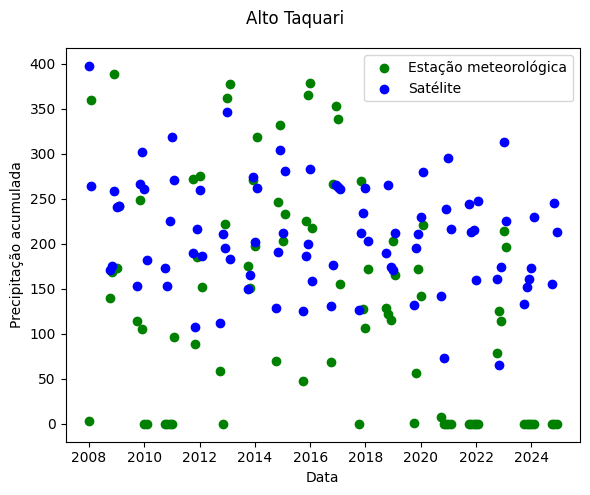

In [13]:
for file in os.listdir(r"Bases\Dados INMET - validacao"):
    aux_name = pd.read_csv("Bases/Dados INMET - validacao/" + file, nrows=0).columns[0].split(':')[1].strip().title()
    if aux_name != "Alto Taquari":
        continue

    aux = pd.read_csv("Bases/Dados INMET - validacao/" + file, skiprows=10, sep=';')
    aux.columns = ['Data', 'precip_inmet', 'temp_inmet', 'fodase']
    aux = aux[['Data', 'precip_inmet', 'temp_inmet']]
    aux['Data'] = pd.to_datetime(aux['Data'], format='%Y-%m-%d').dt.to_period('M').dt.to_timestamp()
    aux = aux[aux['Data'].dt.month.isin([1, 2, 10, 11, 12])]
    
    aux = aux.groupby('Data').agg({
        'precip_inmet': 'sum',
        'temp_inmet': 'max'
        }).reset_index()
    
    fig, ax = plt.subplots(1, 1, figsize=(6,5))
    # ax = ax.flatten()

    satelite_aux = satelite[satelite['NM_MUN'] == aux_name]
    satelite_aux = satelite_aux[satelite_aux['DATA'].dt.month.isin([1, 2, 10, 11, 12])]
    start = max(aux['Data'].min(), satelite_aux['DATA'].min())
    end   = min(aux['Data'].max(), satelite_aux['DATA'].max())
    aux = aux[(aux['Data'] >= start) & (aux['Data'] <= end)]
    satelite_aux = satelite_aux[(satelite_aux['DATA'] >= start) & (satelite_aux['DATA'] <= end)]

    ### Plot de precipitacao
    # ax.set_title('Precipitação acumulada histórica')
    ax.scatter(aux['Data'], aux['precip_inmet'], color='g', label='Estação meteorológica')
    ax.scatter(satelite_aux['DATA'], satelite_aux['precip'], color='b', label='Satélite')
    ax.legend()

    ax.set_xlabel('Data')
    ax.set_ylabel('Precipitação acumulada')
    fig.suptitle(aux_name)
    plt.tight_layout()
    plt.show()

In [88]:
aux['precip_inmet'].value_counts()

precip_inmet
0.0      25
359.8     1
139.6     1
168.6     1
3.2       1
         ..
78.8      1
125.4     1
114.6     1
213.8     1
196.2     1
Name: count, Length: 61, dtype: int64

In [42]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
array = []

for file in os.listdir(r"Bases\Dados INMET - validacao"):
    aux_name = pd.read_csv("Bases/Dados INMET - validacao/" + file, nrows=0).columns[0].split(':')[1].strip().title()
    if aux_name not in satelite['NM_MUN'].unique():
        continue

    aux = pd.read_csv("Bases/Dados INMET - validacao/" + file, skiprows=10, sep=';')
    aux.columns = ['Data', 'precip_inmet', 'temp_inmet', 'fodase']
    aux = aux[['Data', 'precip_inmet', 'temp_inmet']]
    aux['Data'] = pd.to_datetime(aux['Data'], format='%Y-%m-%d').dt.to_period('M').dt.to_timestamp()
    aux = aux[aux['Data'].dt.month.isin([1,2, 10,11,12])]
    aux = aux.groupby('Data').agg({
        'precip_inmet': 'sum',
        'temp_inmet': 'max'
        }).reset_index()
    
    satelite_aux = satelite[satelite['NM_MUN'] == aux_name]
    satelite_aux = satelite_aux[satelite_aux['DATA'].dt.month.isin([1, 2, 10, 11, 12])]

    aux = aux.merge(satelite_aux, how='inner', left_on='Data', right_on='DATA')
    aux = aux.dropna()

    msd_precip = mean_absolute_error(aux['precip_inmet'], aux['precip'])
    msd_temp = mean_absolute_error(aux['temp_inmet'], aux['t2m'])
    rmsd_precip = root_mean_squared_error(aux['precip_inmet'], aux['precip'])
    rmsd_temp = root_mean_squared_error(aux['temp_inmet'], aux['t2m'])
    array.append([aux_name, msd_precip, msd_temp, rmsd_precip, rmsd_temp])

array = pd.DataFrame(array, columns=['Município', 'MAD Precip', 'MAD Temp', 'RMSD Precip', 'RMSD Temp']).round(2).astype(str)
multi_cols = pd.MultiIndex.from_tuples([
    ('', "Município"),
    ('MAD', 'Precip '), ('MAD', 'Temp '),
    ('RMSD', 'Precip '), ('RMSD', 'Temp ')
])

array.columns = multi_cols


print(array.to_latex(index=False))

\begin{tabular}{lllll}
\toprule
 & \multicolumn{2}{r}{MAD} & \multicolumn{2}{r}{RMSD} \\
Município & Precip  & Temp  & Precip  & Temp  \\
\midrule
Pires Do Rio & 53.54 & 1.5 & 71.55 & 1.69 \\
Uberlandia & 48.24 & 0.68 & 69.74 & 0.83 \\
Uberaba & 75.36 & 0.63 & 98.83 & 0.74 \\
Castro & 66.55 & 0.76 & 90.89 & 0.9 \\
Xanxere & 60.78 & 1.06 & 88.81 & 1.38 \\
Chapeco & 38.82 & 0.82 & 60.26 & 1.27 \\
Alto Taquari & 109.68 & 0.66 & 138.37 & 0.89 \\
\bottomrule
\end{tabular}



In [ ]:


for file in os.listdir(r"Bases\Dados INMET - validacao"):
    aux = pd.read_csv("Bases/Dados INMET - validacao/" + file, skiprows=10, sep=';')
    aux_name = pd.read_csv("Bases/Dados INMET - validacao/" + file, nrows=0).columns[0].split(':')[1].strip().title()
    aux.columns = ['Data', 'precip_inmet', 'temp_inmet', 'fodase']
    aux = aux[['Data', 'precip_inmet', 'temp_inmet']]
    aux['Data'] = pd.to_datetime(aux['Data'], format='%Y-%m-%d').dt.to_period('M').dt.to_timestamp()
    aux = aux[aux['Data'].dt.month.isin([1,2,10,11,12])]
    aux = aux.groupby('Data').agg({
        'precip_inmet': 'sum',
        'temp_inmet': 'max'
        }).reset_index()
    
    satelite_aux = satelite[satelite['NM_MUN'] == aux_name]

    aux = aux.merge(satelite_aux, how='inner', left_on='Data', right_on='time')
    # aux = aux.dropna()
    aux = aux[aux['precip_inmet'] > 0]


    print(aux_name)
    print("MAE Precipitação:", mse_precip)
    print("MAE Temperatura:", mse_temp)

    print(f"MAE Precipitação (% inmet): {100* (mse_precip)/aux['precip_inmet'].mean():.2f}%")
    print(f"MAE Temperatura: (% INMET) {100* (mse_temp)/aux['temp_inmet'].mean():.2f}%")
    print()

Pires Do Rio
MAE Precipitação: 51.32021372881356
MAE Temperatura: 1.5000301694915028
MAE Precipitação (% inmet): 27.32%
MAE Temperatura: (% INMET) 4.32%

Xinguara
MAE Precipitação: 55.56925760000001
MAE Temperatura: 0.818209599999991
MAE Precipitação (% inmet): 35.98%
MAE Temperatura: (% INMET) 2.36%

Barra
MAE Precipitação: 35.69918417307692
MAE Temperatura: 0.7620103846153803
MAE Precipitação (% inmet): 36.03%
MAE Temperatura: (% INMET) 2.00%

Uberlandia
MAE Precipitação: 48.7468428125
MAE Temperatura: 0.6951221874999994
MAE Precipitação (% inmet): 22.51%
MAE Temperatura: (% INMET) 2.07%

Uberaba
MAE Precipitação: 68.27635096
MAE Temperatura: 0.6506743999999857
MAE Precipitação (% inmet): 32.15%
MAE Temperatura: (% INMET) 1.90%

Castro
MAE Precipitação: 58.75177264705882
MAE Temperatura: 0.7604760784313714
MAE Precipitação (% inmet): 41.19%
MAE Temperatura: (% INMET) 2.43%

Xanxere
MAE Precipitação: 58.149437129032265
MAE Temperatura: 1.073197419354854
MAE Precipitação (% inmet): 31.

In [36]:
aux[['Data', 'precip_inmet', 'precip', 'temp_inmet', 't2m']]

,Data,precip_inmet,precip,temp_inmet,t2m
0,2008-01-01,3.2,397.886700,28.9,31.30605
1,2008-10-01,139.6,171.168720,36.6,36.76846
2,2008-11-01,168.6,175.183120,32.2,33.78213
3,2008-12-01,389.2,258.858340,32.8,32.53213
4,2009-01-01,172.8,240.549820,34.1,33.72770
5,2009-10-01,114.0,153.259670,34.2,33.38223
6,2009-11-01,249.0,266.455630,33.6,33.16958
7,2009-12-01,105.2,301.624570,31.5,30.60000
13,2011-10-01,271.8,189.758100,32.8,33.99526
14,2011-11-01,88.4,107.193380,32.0,34.31730


mudar nomeclatura para diferença absoluta; onde elas sao maiores?

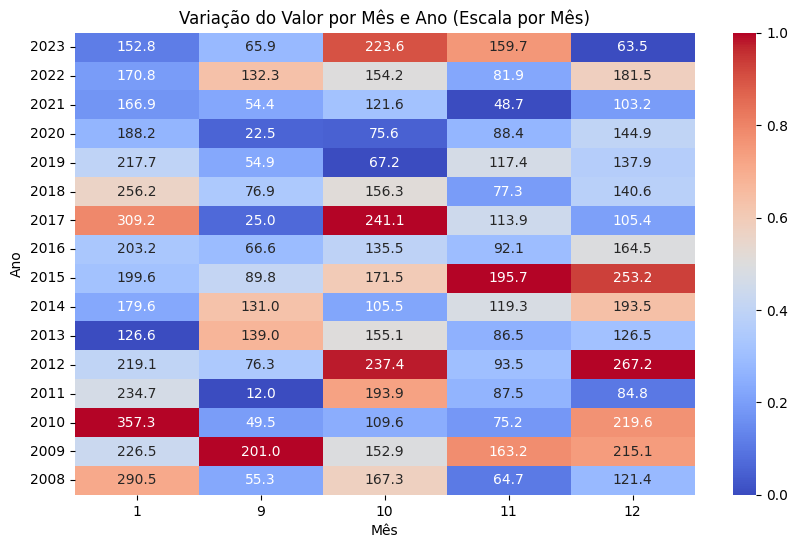

In [14]:
prec = pd.read_csv('Bases/precip_range(2008, 2024).csv', encoding='latin1')

prec['time'] = pd.to_datetime(prec['time'], format='%Y-%m-%d')
prec['Mes'] = prec['time'].dt.month
prec['Ano'] = prec['time'].dt.year

prec = prec[prec['NM_MUN'] == 'Capão Bonito'].dropna(subset=['precip'])
prec  = prec.pivot(index='Ano', columns='Mes', values='precip').sort_values(by='Ano', ascending=False)

tabela_norm = prec.copy()
tabela_norm = (tabela_norm - tabela_norm.min()) / (tabela_norm.max() - tabela_norm.min())

plt.figure(figsize=(10,6))
sns.heatmap(tabela_norm, cmap='coolwarm', annot=prec, fmt=".1f")
plt.title('Variação do Valor por Mês e Ano (Escala por Mês)')
plt.xlabel('Mês')
plt.ylabel('Ano')
plt.show()

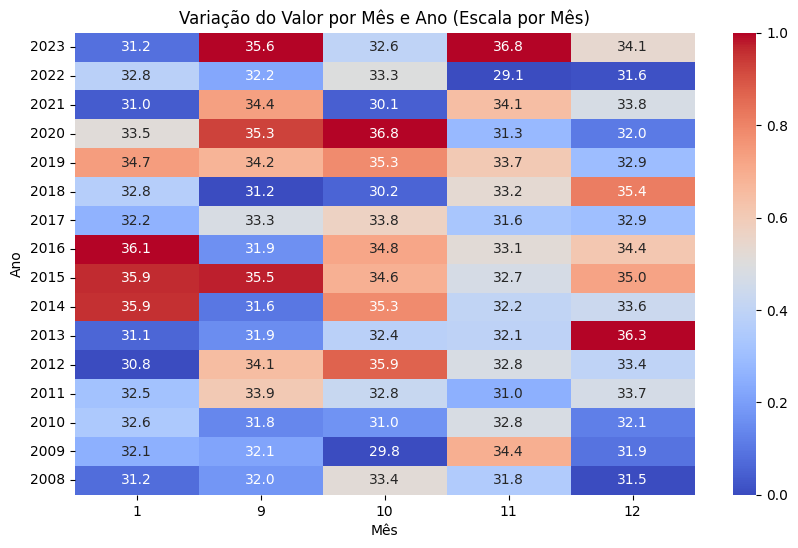

In [15]:
temp = pd.read_csv('Bases/temperature_range(2008, 2024).csv', encoding='latin1')
temp['t2m'] = temp['t2m'] - 273.15
temp['time'] = pd.to_datetime(temp['time'], format='%Y-%m-%d')
temp['Mes'] = temp['time'].dt.month
temp['Ano'] = temp['time'].dt.year

temp = temp[temp['NM_MUN'] == 'Capão Bonito'].dropna(subset=['t2m'])
temp  = temp.pivot(index='Ano', columns='Mes', values='t2m').sort_values(by='Ano', ascending=False)

tabela_norm = temp.copy()
tabela_norm = (tabela_norm - tabela_norm.min()) / (tabela_norm.max() - tabela_norm.min())

plt.figure(figsize=(10,6))
sns.heatmap(tabela_norm, cmap='coolwarm', annot=temp, fmt=".1f")
plt.title('Variação do Valor por Mês e Ano (Escala por Mês)')
plt.xlabel('Mês')
plt.ylabel('Ano')
plt.show()


In [16]:
ndvi = pd.read_csv("Bases/ndvi_range(2008, 2024).csv", encoding='latin1')
ndvi

,NM_MUN,SIGLA_UF,time,ndvi
0,Abaeté,MG,2008-01-01,5217783.5
1,Abaeté,MG,2008-02-01,5805101.5
2,Abaeté,MG,2008-09-01,3804726.5
3,Abaeté,MG,2008-10-01,4242231.0
4,Abaeté,MG,2008-11-01,4702033.0
...,...,...,...,...
47995,Áurea,RS,2023-02-01,8191531.5
47996,Áurea,RS,2023-09-01,7363396.5
47997,Áurea,RS,2023-10-01,6419444.5
47998,Áurea,RS,2023-11-01,5018277.5


C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_11892\1090736657.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exemplo['time'] = pd.to_datetime(exemplo['time'], format='%Y-%m-%d')


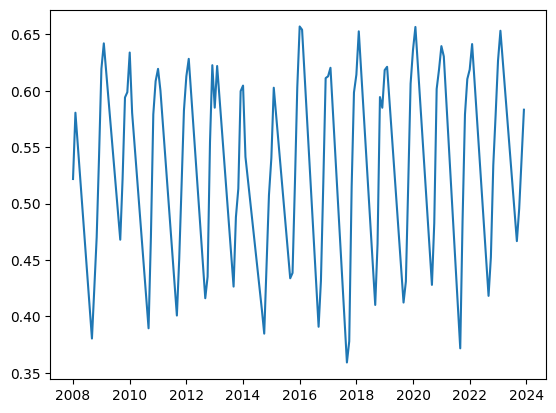

In [17]:
exemplo = ndvi[ndvi['NM_MUN'] == 'Abaeté']
exemplo['time'] = pd.to_datetime(exemplo['time'], format='%Y-%m-%d')
plt.plot(exemplo['time'], exemplo['ndvi']/1e7)
plt.show()

* visualizacao depois das transformadas?